# Crime Case Resolution Analysis
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
A city police headquarters wants to understand **what makes some FIR cases take longer to close** so that senior officers can decide how to assign staff and which cases to watch closely.

**Questions we will answer**
1. What does the resolution time (`Resolution_Days`) look like overall?
2. Do reporting delay and officers assigned affect resolution time?
3. Does resolution time differ by city, crime type, severity or reporting mode?
4. Which cases need attention (resolution time above 75 days = At Risk)?

> The dataset is **synthetic** (computer-generated) and contains no real crime or personal data.

## 2. Import libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [9]:
df = pd.read_csv('../Data/Raw/Crime Data.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 12)


,Case_ID,FIR_Date,City,Crime_Type,Severity,Reporting_Mode,Officers_Assigned,Reporting_Delay_Hours,Witness_Count,Complainant_Age,Loss_Amount_INR,Resolution_Days
0,C1023,2025-09-23,Bengaluru,Theft,Low,Online,2,59,0.0,34.0,25600.0,74
1,C1070,2025-07-14,Kolkata,Theft,Low,Online,3,34,1.0,18.0,18700.0,54
2,C1228,2025-06-06,Bengaluru,Cyber Crime,High,Police Station,5,98,3.0,29.0,56300.0,91
3,C1232,2026-03-02,Mumbai,Assault,Low,Police Station,4,66,2.0,43.0,283600.0,45
4,C1134,2024-12-29,Delhi,Cyber Crime,Low,Police Station,1,47,0.0,58.0,82400.0,65


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Case_ID                255 non-null    str    
 1   FIR_Date               255 non-null    str    
 2   City                   255 non-null    str    
 3   Crime_Type             255 non-null    str    
 4   Severity               255 non-null    str    
 5   Reporting_Mode         250 non-null    str    
 6   Officers_Assigned      255 non-null    int64  
 7   Reporting_Delay_Hours  255 non-null    int64  
 8   Witness_Count          250 non-null    float64
 9   Complainant_Age        250 non-null    float64
 10  Loss_Amount_INR        250 non-null    float64
 11  Resolution_Days        255 non-null    int64  
dtypes: float64(3), int64(3), str(6)
memory usage: 24.0 KB


In [11]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Reporting_Mode     5
Witness_Count      5
Complainant_Age    5
Loss_Amount_INR    5
dtype: int64

Duplicate rows: 5


,Officers_Assigned,Reporting_Delay_Hours,Witness_Count,Complainant_Age,Loss_Amount_INR,Resolution_Days
count,255.0,255.0,250.0,250.0,250.0,255.0
mean,2.8,43.5,2.0,38.6,94515.2,52.2
std,1.4,30.8,1.4,17.5,133479.6,19.0
min,1.0,1.0,0.0,-29.0,1800.0,4.0
25%,2.0,23.0,1.0,28.0,20350.0,40.0
50%,3.0,37.0,2.0,37.0,46750.0,53.0
75%,4.0,58.5,3.0,48.0,123400.0,64.5
max,6.0,206.0,8.0,214.0,1146800.0,131.0


**What we found:** some missing values, duplicate rows, inconsistent text in `City` (e.g. `mumbai`, `CHENNAI`, extra spaces) and impossible values in `Complainant_Age` (a negative age and an age above 100). We clean these next.

## 4. Clean the data

In [12]:
clean = df.copy()
clean = clean.drop_duplicates()
clean['City'] = clean['City'].str.strip().str.title()
clean.loc[(clean['Complainant_Age']<18)|(clean['Complainant_Age']>80),'Complainant_Age'] = np.nan
num_cols = ['Officers_Assigned','Reporting_Delay_Hours','Witness_Count','Complainant_Age','Loss_Amount_INR','Resolution_Days']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
clean['Reporting_Mode'] = clean['Reporting_Mode'].fillna(clean['Reporting_Mode'].mode()[0])
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [13]:
clean['Loss_Per_Officer'] = (clean['Loss_Amount_INR']/clean['Officers_Assigned']).round(0)
def status(d):
    if d>75: return 'At Risk'
    if d>60: return 'Delayed'
    if d>40: return 'On Track'
    return 'Fast'
clean['Case_Status'] = clean['Resolution_Days'].apply(status)
clean['Delay_Band'] = pd.cut(clean['Reporting_Delay_Hours'],[0,24,72,120,500],labels=['<24h','1-3 days','3-5 days','>5 days'],right=False)
clean[['Case_ID','Loss_Per_Officer','Case_Status','Delay_Band']].head()

,Case_ID,Loss_Per_Officer,Case_Status,Delay_Band
0,C1023,12800.0,Delayed,1-3 days
1,C1070,6233.0,On Track,1-3 days
2,C1228,11260.0,At Risk,3-5 days
3,C1232,70900.0,On Track,1-3 days
4,C1134,82400.0,Delayed,1-3 days


## 6. Exploratory Data Analysis (EDA)

### Q1. Overall resolution time

count    250.0
mean      52.3
std       19.1
min        4.0
25%       40.0
50%       53.0
75%       64.8
max      131.0
Name: Resolution_Days, dtype: float64


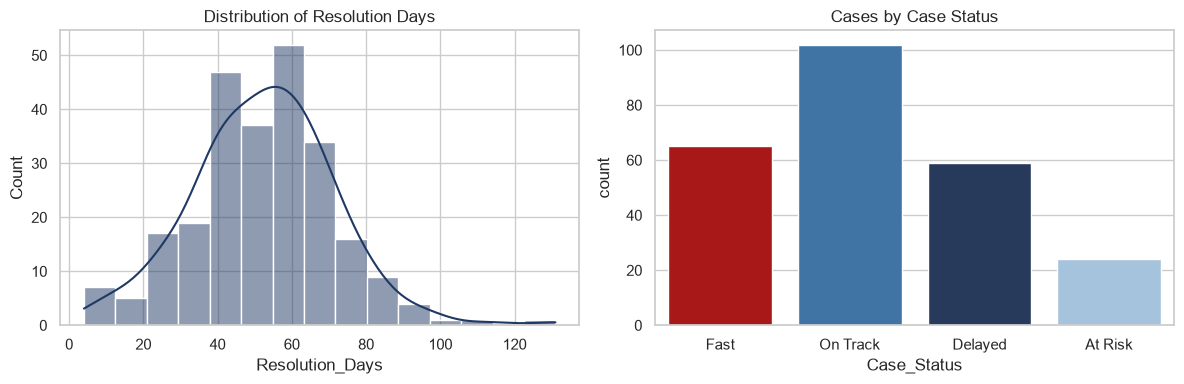

In [14]:
print(clean['Resolution_Days'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Resolution_Days'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Resolution Days')
order=['Fast','On Track','Delayed','At Risk']
sns.countplot(data=clean,x='Case_Status',hue='Case_Status',legend=False,order=order,palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1]);ax[1].set_title('Cases by Case Status')
plt.tight_layout();plt.savefig('../images/01_overall_resolution.png');plt.show()

### Q2. Do reporting delay and officers assigned affect resolution time?

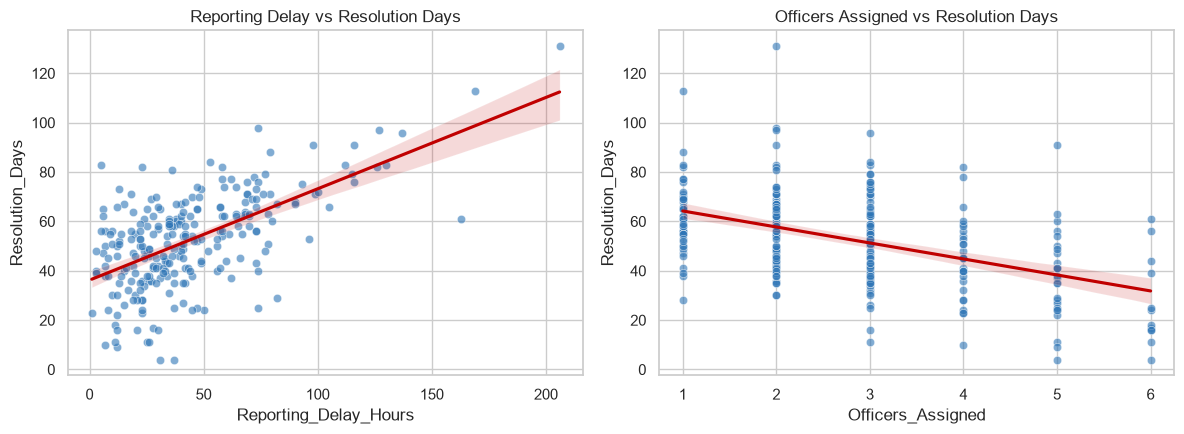

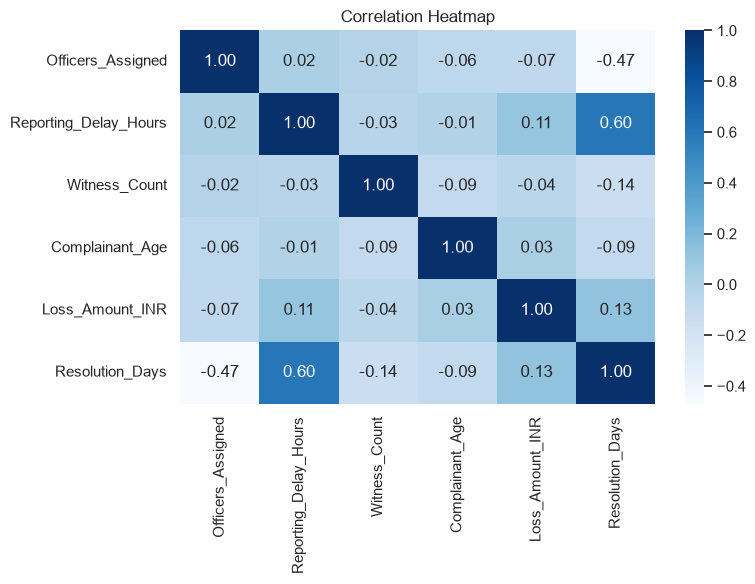

In [15]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Reporting_Delay_Hours',y='Resolution_Days',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Reporting_Delay_Hours',y='Resolution_Days',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Reporting Delay vs Resolution Days')
sns.scatterplot(data=clean,x='Officers_Assigned',y='Resolution_Days',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Officers_Assigned',y='Resolution_Days',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Officers Assigned vs Resolution Days')
plt.tight_layout();plt.savefig('../images/02_delay_officers.png');plt.show()
plt.figure(figsize=(8,6))
sns.heatmap(clean[num_cols].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/03_correlation.png');plt.show()

In [16]:
print(clean.groupby('Delay_Band',observed=True)['Resolution_Days'].agg(['count','mean']).round(1))

            count  mean
Delay_Band             
<24h           69  42.8
1-3 days      141  51.5
3-5 days       33  66.6
>5 days         7  94.7


### Q3. Does resolution time differ by city, crime type, severity or reporting mode?

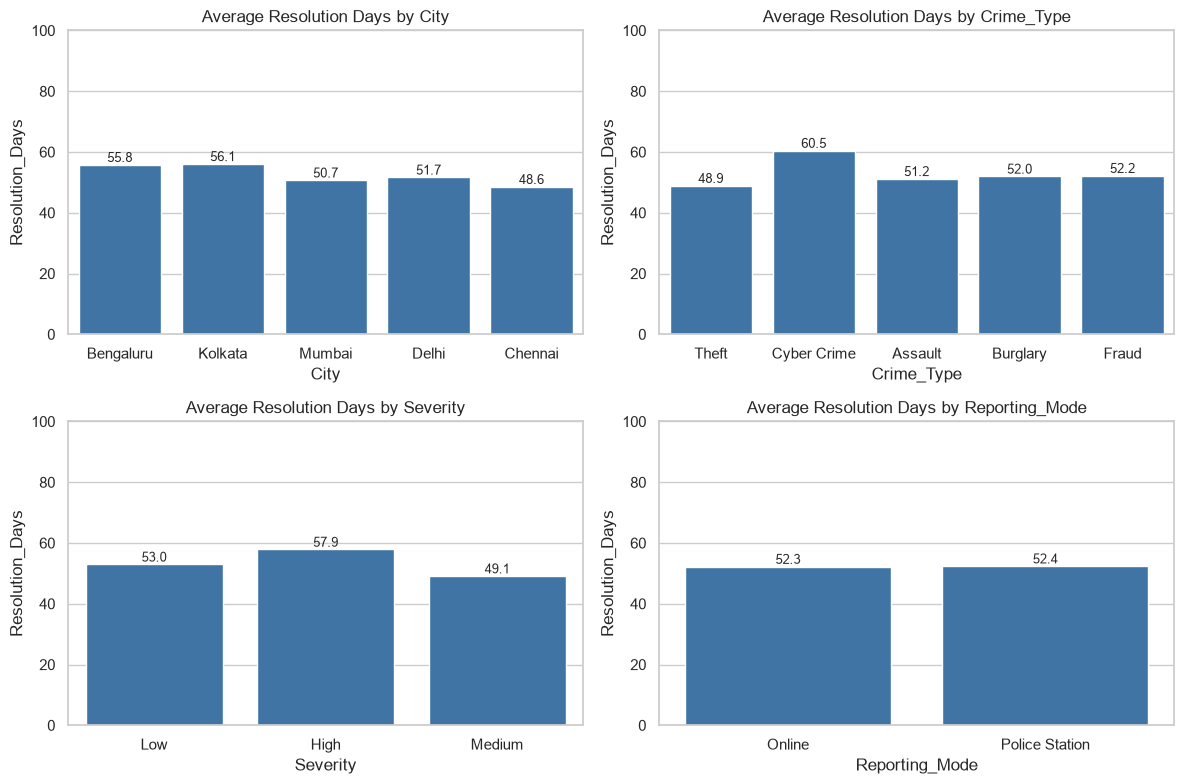

In [17]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['City','Crime_Type','Severity','Reporting_Mode']):
    sns.barplot(data=clean,x=col,y='Resolution_Days',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Resolution Days by {col}');a.set_ylim(0,100)
    for p in a.patches:a.annotate(f'{p.get_height():.1f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.savefig('../images/04_group_comparison.png');plt.show()

### Q4. Which cases need attention?

In [18]:
risk = clean[clean['Case_Status']=='At Risk'].sort_values('Resolution_Days',ascending=False)
print(f'{len(risk)} cases ({len(risk)/len(clean):.1%}) are At Risk')
print('Average reporting delay of At Risk cases:', round(risk['Reporting_Delay_Hours'].mean(),1),'hours vs overall', round(clean['Reporting_Delay_Hours'].mean(),1),'hours')
risk[['Case_ID','City','Crime_Type','Reporting_Delay_Hours','Officers_Assigned','Resolution_Days']].head(10)

24 cases (9.6%) are At Risk
Average reporting delay of At Risk cases: 91.3 hours vs overall 43.6 hours


,Case_ID,City,Crime_Type,Reporting_Delay_Hours,Officers_Assigned,Resolution_Days
53,C1056,Bengaluru,Fraud,206,2,131
252,C1037,Mumbai,Cyber Crime,169,1,113
37,C1227,Bengaluru,Cyber Crime,74,2,98
240,C1084,Delhi,Assault,127,2,97
30,C1080,Bengaluru,Burglary,137,3,96
181,C1188,Bengaluru,Assault,116,2,91
2,C1228,Bengaluru,Cyber Crime,98,5,91
47,C1031,Mumbai,Theft,79,1,88
108,C1210,Kolkata,Fraud,53,3,84
150,C1086,Chennai,Cyber Crime,5,1,83


## 7. Key insights (generated from the data)

In [19]:
r_del=clean['Reporting_Delay_Hours'].corr(clean['Resolution_Days']);r_off=clean['Officers_Assigned'].corr(clean['Resolution_Days'])
slow=clean.groupby('Crime_Type')['Resolution_Days'].mean().idxmax();fast=clean.groupby('Crime_Type')['Resolution_Days'].mean().idxmin()
mode=clean.groupby('Reporting_Mode')['Resolution_Days'].mean()
print(f"1. Average resolution time: {clean['Resolution_Days'].mean():.1f} days; median {clean['Resolution_Days'].median():.1f} days.")
print(f"2. Reporting delay vs resolution days correlation = {r_del:.2f} (positive); officers assigned vs resolution days = {r_off:.2f} (negative).")
print(f"3. Slowest crime type: {slow}; fastest: {fast}.")
print(f"4. Cases reported online average {mode['Online']:.1f} days vs {mode['Police Station']:.1f} at a police station.")
print(f"5. {len(risk)} cases are At Risk; their average reporting delay is {risk['Reporting_Delay_Hours'].mean():.0f} hours.")

1. Average resolution time: 52.3 days; median 53.0 days.
2. Reporting delay vs resolution days correlation = 0.60 (positive); officers assigned vs resolution days = -0.47 (negative).
3. Slowest crime type: Cyber Crime; fastest: Theft.
4. Cases reported online average 52.3 days vs 52.4 at a police station.
5. 24 cases are At Risk; their average reporting delay is 91 hours.


## 8. Recommendations
- Encourage citizens to **report incidents quickly**, ideally within 24 hours, because late reporting is linked to longer resolution times.
- Assign **more officers to complex cases**, especially Cyber Crime and High severity cases, which tend to take longer.
- Review **At Risk cases (over 75 days) every week** and escalate them to a senior officer.

> **Remember:** correlation does not prove causation. This analysis shows association, not cause.

## 9. Save the cleaned data

In [ ]:
clean.to_csv('../Data/Processed/Crime Data Processed.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
